# House Price Prediction Project
This section includes library imports and initial environment setup.

In [108]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import random

import joblib
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.compose import TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report, recall_score, precision_score, roc_auc_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

## Stage 1: Data Loading


In [109]:
dataset_path = '/kaggle/input/datasets/juhibhojani/house-price/house_prices.csv'

df = pd.read_csv(dataset_path)
print(f"Dataset successfully loaded from: {dataset_path}")
print("Dataset Shape:", df.shape)

Dataset successfully loaded from: /kaggle/input/datasets/juhibhojani/house-price/house_prices.csv
Dataset Shape: (187531, 21)


In [110]:
df.sample(7)

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
76646,76646,2 BHK Ready to Occupy Flat for sale in ELV Glo...,This exquisite 2 BHK Flat is offered for sale ...,52 Lac,5389.0,hyderabad,NaN,Ready to Move,NaN,Resale,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,965 sqft,NaN,NaN
66414,66414,3 BHK Ready to Occupy Flat for sale in DLF Sky...,This magnificent 3 BHK Flat is available for s...,1.55 Cr,8073.0,gurgaon,NaN,Ready to Move,2 out of 20,Resale,...,North - East,Garden/Park,DLF Skycourt,3,1,NaN,Freehold,1920 sqft,NaN,NaN
151490,151490,3 BHK Ready to Occupy Flat for sale in Imperia...,This attractive 3 BHK apartment can be found f...,65.9 Lac,4545.0,chandigarh,900 sqft,Ready to Move,1 out of 4,New Property,...,North - East,"Garden/Park, Pool, Main Road",Imperial Apartments,3,3,"1 Covered,",Freehold,NaN,NaN,NaN
85651,85651,2 BHK Ready to Occupy Flat for sale Jhotwara,This exquisite 2 BHK Flat is offered for sale ...,24 Lac,2667.0,jaipur,NaN,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,2,NaN,NaN,NaN,900 sqft,NaN,NaN
103500,103500,2 BHK Ready to Occupy Flat for sale Shyamnagar,This beautiful 2 BHK Flat is available for sal...,25 Lac,3676.0,kolkata,NaN,Ready to Move,4 out of 4,Resale,...,NaN,NaN,NaN,1,NaN,NaN,NaN,680 sqft,NaN,NaN
116430,116430,4 BHK Ready to Occupy Flat for sale Surajmal V...,This magnificent 4 BHK Flat is available for s...,5.50 Cr,28646.0,new-delhi,1920 sqft,Ready to Move,4 out of 4,Resale,...,North,"Pool, Garden/Park, Main Road",NaN,4,4,NaN,Freehold,NaN,NaN,NaN
70950,70950,3 BHK Ready to Occupy Flat for sale in Aparna ...,This ready to move-in 3 BHK flat is available ...,1.75 Cr,9589.0,hyderabad,NaN,Ready to Move,2 out of 2,Resale,...,NaN,NaN,NaN,3,2,NaN,NaN,1825 sqft,NaN,NaN


In [111]:
df.columns

Index(['Index', 'Title', 'Description', 'Amount(in rupees)',
       'Price (in rupees)', 'location', 'Carpet Area', 'Status', 'Floor',
       'Transaction', 'Furnishing', 'facing', 'overlooking', 'Society',
       'Bathroom', 'Balcony', 'Car Parking', 'Ownership', 'Super Area',
       'Dimensions', 'Plot Area'],
      dtype='object')

In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Index              187531 non-null  int64  
 1   Title              187531 non-null  object 
 2   Description        184508 non-null  object 
 3   Amount(in rupees)  187531 non-null  object 
 4   Price (in rupees)  169866 non-null  float64
 5   location           187531 non-null  object 
 6   Carpet Area        106858 non-null  object 
 7   Status             186916 non-null  object 
 8   Floor              180454 non-null  object 
 9   Transaction        187448 non-null  object 
 10  Furnishing         184634 non-null  object 
 11  facing             117298 non-null  object 
 12  overlooking        106095 non-null  object 
 13  Society            77853 non-null   object 
 14  Bathroom           186703 non-null  object 
 15  Balcony            138596 non-null  object 
 16  Ca

## Stage 2: Data Preprocessing
Cleaning the data, handling missing values, and removing unnecessary columns.

In [113]:
df = df.rename(columns={'Amount(in rupees)': 'amount_in_rupees'})
df = df.rename(columns={'Price (in rupees)': 'price_in_rupees'})
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')


In [114]:
df.isnull().sum()/len(df)*100

index                 0.000000
title                 0.000000
description           1.612000
amount_in_rupees      0.000000
price_in_rupees       9.419776
location              0.000000
carpet_area          43.018488
status                0.327946
floor                 3.773776
transaction           0.044259
furnishing            1.544811
facing               37.451408
overlooking          43.425354
society              58.485264
bathroom              0.441527
balcony              26.094352
car_parking          55.114621
ownership            34.936624
super_area           57.422506
dimensions          100.000000
plot_area           100.000000
dtype: float64

<Axes: >

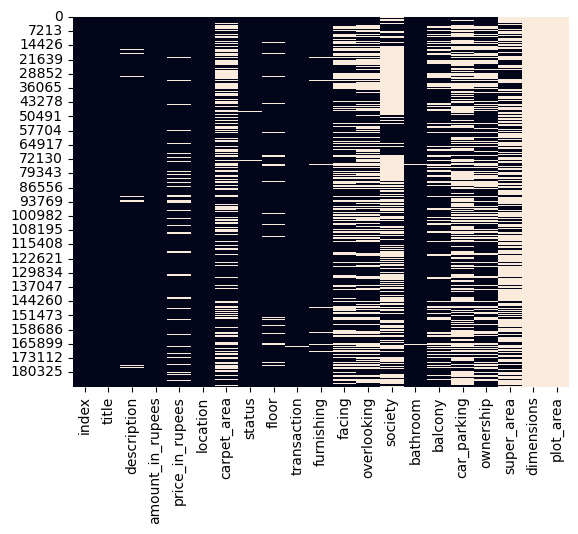

In [115]:
sns.heatmap(df.isnull(),cbar=0)

In [116]:
df.drop(columns=['society', 'car_parking', 'super_area', 'dimensions', 'plot_area'], inplace=True)
df.drop(columns=['index', 'title', 'description','overlooking'], inplace=True)

In [117]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   amount_in_rupees  187531 non-null  object 
 1   price_in_rupees   169866 non-null  float64
 2   location          187531 non-null  object 
 3   carpet_area       106858 non-null  object 
 4   status            186916 non-null  object 
 5   floor             180454 non-null  object 
 6   transaction       187448 non-null  object 
 7   furnishing        184634 non-null  object 
 8   facing            117298 non-null  object 
 9   bathroom          186703 non-null  object 
 10  balcony           138596 non-null  object 
 11  ownership         122014 non-null  object 
dtypes: float64(1), object(11)
memory usage: 17.2+ MB


In [118]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price_in_rupees,169866.0,7583.771885,27241.705819,0.0,4297.0,6034.0,9450.0,6700000.0


In [119]:
df.describe(include='O')

,amount_in_rupees,location,carpet_area,status,floor,transaction,furnishing,facing,bathroom,balcony,ownership
count,187531,187531,106858,186916,180454,187448,184634,117298,186703,138596,122014
unique,1561,81,2758,1,947,4,3,8,11,11,4
top,Call for Price,new-delhi,1000 sqft,Ready to Move,2 out of 4,Resale,Semi-Furnished,East,2,2,Freehold
freq,9684,27599,5285,186916,12433,144172,88318,54741,93007,51809,112229


In [120]:
df['bathroom'] = pd.to_numeric(df['bathroom'], errors='coerce')
df['balcony'] = pd.to_numeric(df['balcony'], errors='coerce')

In [121]:
col_fill_unknow=['ownership','facing']
df[col_fill_unknow]=df[col_fill_unknow].fillna('Unknown')

In [122]:
def convert_amount(amount):
    try:
        if 'Lac' in amount:
            amount = amount.replace('Lac', '').strip()
            return float(amount) * 100000  # Convert Lac to rupees (1 Lac = 100000 rupees)
        elif 'Cr' in amount:
            amount = amount.replace('Cr', '').strip()
            return float(amount) * 10000000  # Convert Cr to rupees (1 Cr = 10000000 rupees)
        else:
            return float(amount)
    except ValueError:
        return None

df['amount_in_rupees'] = df['amount_in_rupees'].apply(convert_amount)

In [123]:
print(df['location'].value_counts().head(40))

location
new-delhi        27599
bangalore        24030
kolkata          22380
gurgaon          20070
ahmedabad        12750
hyderabad        12300
chennai          10500
jaipur            8490
greater-noida     4710
faridabad         3840
vadodara          2388
surat             2370
pune              2225
thane             1933
mumbai            1860
visakhapatnam     1800
mohali            1710
zirakpur          1530
chandigarh        1440
noida             1281
goa               1200
ranchi            1080
bhiwadi           1050
kochi             1050
dehradun           990
ghaziabad          931
lucknow            896
kanpur             780
patna              780
sonipat            750
guwahati           750
coimbatore         720
navi-mumbai        718
nagpur             714
jamshedpur         630
kalyan             600
vijayawada         570
palghar            510
raipur             510
bhubaneswar        456
Name: count, dtype: int64


In [124]:

location_stats = df['location'].value_counts()
locations_less_than_500 = location_stats[location_stats <= 500]

df['location'] = df['location'].apply(
    lambda x: 'other' if x in locations_less_than_500 else x
)

len(df['location'].unique())

40

In [125]:
df['ownership'].value_counts()

ownership
Freehold                112229
Unknown                  65517
Leasehold                 5285
Co-operative Society      3431
Power Of Attorney         1069
Name: count, dtype: int64

In [126]:
df['facing'].value_counts()

facing
Unknown         70233
East            54741
North - East    24220
North           16533
West             8574
South            4694
North - West     3843
South - East     2622
South -West      2071
Name: count, dtype: int64

In [127]:
df['carpet_area']

0          500 sqft
1          473 sqft
2          779 sqft
3          530 sqft
4          635 sqft
            ...    
187526          NaN
187527          NaN
187528    1250 sqft
187529          NaN
187530          NaN
Name: carpet_area, Length: 187531, dtype: object

In [128]:
def convert_carpet_area(area):
    try:
        if isinstance(area, str):
            if 'sqft' in area:
                area = area.replace('sqft', '').strip()
                return float(area)  # Convert to square feet
            elif 'sqm' in area:
                area = area.replace('sqm', '').strip()
                return float(area) * 10.7639  # Convert square meters to square feet (1 sqm = 10.7639 sqft)
        return float(area)
    except ValueError:
        return None

df['carpet_area'] = df['carpet_area'].apply(convert_carpet_area)

df['carpet_area'] = df['carpet_area'].fillna(0)

In [129]:
df['status'].value_counts()

status
Ready to Move    186916
Name: count, dtype: int64

In [130]:
df = df.rename(columns={'status': 'is_ready_to_move'})
df['is_ready_to_move']=df['is_ready_to_move'].apply(lambda x: 1 if x=='Ready To Move' else 0)
df['is_ready_to_move'].value_counts()

is_ready_to_move
0    187531
Name: count, dtype: int64

In [131]:
df = df.drop(columns=['is_ready_to_move'])

In [132]:
df['floor'].value_counts()

floor
2 out of 4                  12433
1 out of 4                  11985
3 out of 4                   8792
1 out of 3                   7093
4 out of 4                   6253
                            ...  
32 out of 33                    1
Lower Basement out of 23        1
Ground out of 29                1
12                              1
7 out of 70                     1
Name: count, Length: 947, dtype: int64

In [133]:
df[['n_floor', 'total_floor']] = df['floor'].str.split(' out of ', expand=True)


floor_map = {
    'Ground': 0,
    'Upper Basement': -1,
    'Lower Basement': -2
}


df['n_floor'] = df['n_floor'].replace(floor_map)
df['n_floor'] = df['n_floor'].fillna(0)


total_floor_map = {
    'Ground': 1,
    'Upper Basement': 1,
    'Lower Basement': 1
}
df['total_floor'] = df['total_floor'].replace(total_floor_map)


df['total_floor'] = df['total_floor'].fillna(df['n_floor']).replace(0, 1)

df['n_floor'] = df['n_floor'].astype(int)
df['total_floor'] = df['total_floor'].astype(int)

In [134]:
df.drop(columns=['floor'],inplace=True)

In [135]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   amount_in_rupees  177847 non-null  float64
 1   price_in_rupees   169866 non-null  float64
 2   location          187531 non-null  object 
 3   carpet_area       187531 non-null  float64
 4   transaction       187448 non-null  object 
 5   furnishing        184634 non-null  object 
 6   facing            187531 non-null  object 
 7   bathroom          186668 non-null  float64
 8   balcony           138574 non-null  float64
 9   ownership         187531 non-null  object 
 10  n_floor           187531 non-null  int64  
 11  total_floor       187531 non-null  int64  
dtypes: float64(5), int64(2), object(5)
memory usage: 17.2+ MB


In [136]:
fill_mode = ['transaction', 'furnishing', 'ownership']

for col in fill_mode:
    col_mode = df[col].mode()[0]

    df[col] = df[col].fillna(col_mode)

now we still have ( balacons , price and amounts ) i will fill nulls after split data to avoid data leakage

In [137]:
data=df.copy()

In [138]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   amount_in_rupees  177847 non-null  float64
 1   price_in_rupees   169866 non-null  float64
 2   location          187531 non-null  object 
 3   carpet_area       187531 non-null  float64
 4   transaction       187531 non-null  object 
 5   furnishing        187531 non-null  object 
 6   facing            187531 non-null  object 
 7   bathroom          186668 non-null  float64
 8   balcony           138574 non-null  float64
 9   ownership         187531 non-null  object 
 10  n_floor           187531 non-null  int64  
 11  total_floor       187531 non-null  int64  
dtypes: float64(5), int64(2), object(5)
memory usage: 17.2+ MB


In [139]:
valid_conditions = (
    #data = data.dropna(subset=['Amount(in rupees)'])
    (data['amount_in_rupees'] > 0) &


    (data['bathroom'].isna() | ((data['bathroom'] >= 1) & (data['bathroom'] <= 10))) &


    (data['balcony'].isna() | ((data['balcony'] >= 0) & (data['balcony'] <= 6))) &


    (data['n_floor'] >= -2) & (data['n_floor'] <= 80) &


    (data['total_floor'] >= 1) & (data['total_floor'] <= 100) &


    (data['n_floor'] <= data['total_floor'])
)


data = data[valid_conditions].reset_index(drop=True)

print(f"row before: {len(df)}")
print(f"after outliers: {len(data)}")

row before: 187531
after outliers: 177799


In [140]:
Q1 = data['amount_in_rupees'].quantile(0.25)
Q3 = data['amount_in_rupees'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + (3 * IQR)
lower_bound = Q1 - (1.5 * IQR)

data = data[(data['amount_in_rupees'] >= lower_bound) &
            (data['amount_in_rupees'] <= upper_bound)].reset_index(drop=True)


In [141]:
data.shape

(174038, 12)

## Stage 3: Exploratory Data Analysis (EDA)
Visualizing distributions, correlations, and relationships between features and price.

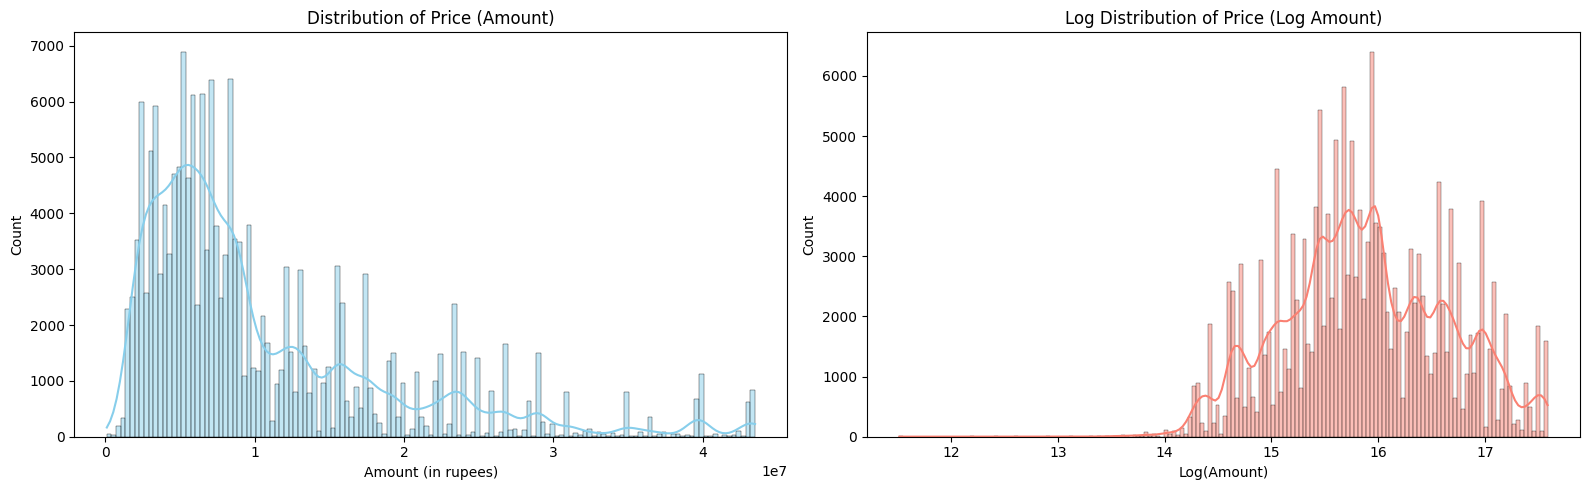

In [142]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(data['amount_in_rupees'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Price (Amount)')
axes[0].set_xlabel('Amount (in rupees)')

sns.histplot(np.log1p(data['amount_in_rupees']), kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Log Distribution of Price (Log Amount)')
axes[1].set_xlabel('Log(Amount)')

plt.tight_layout()
plt.show()

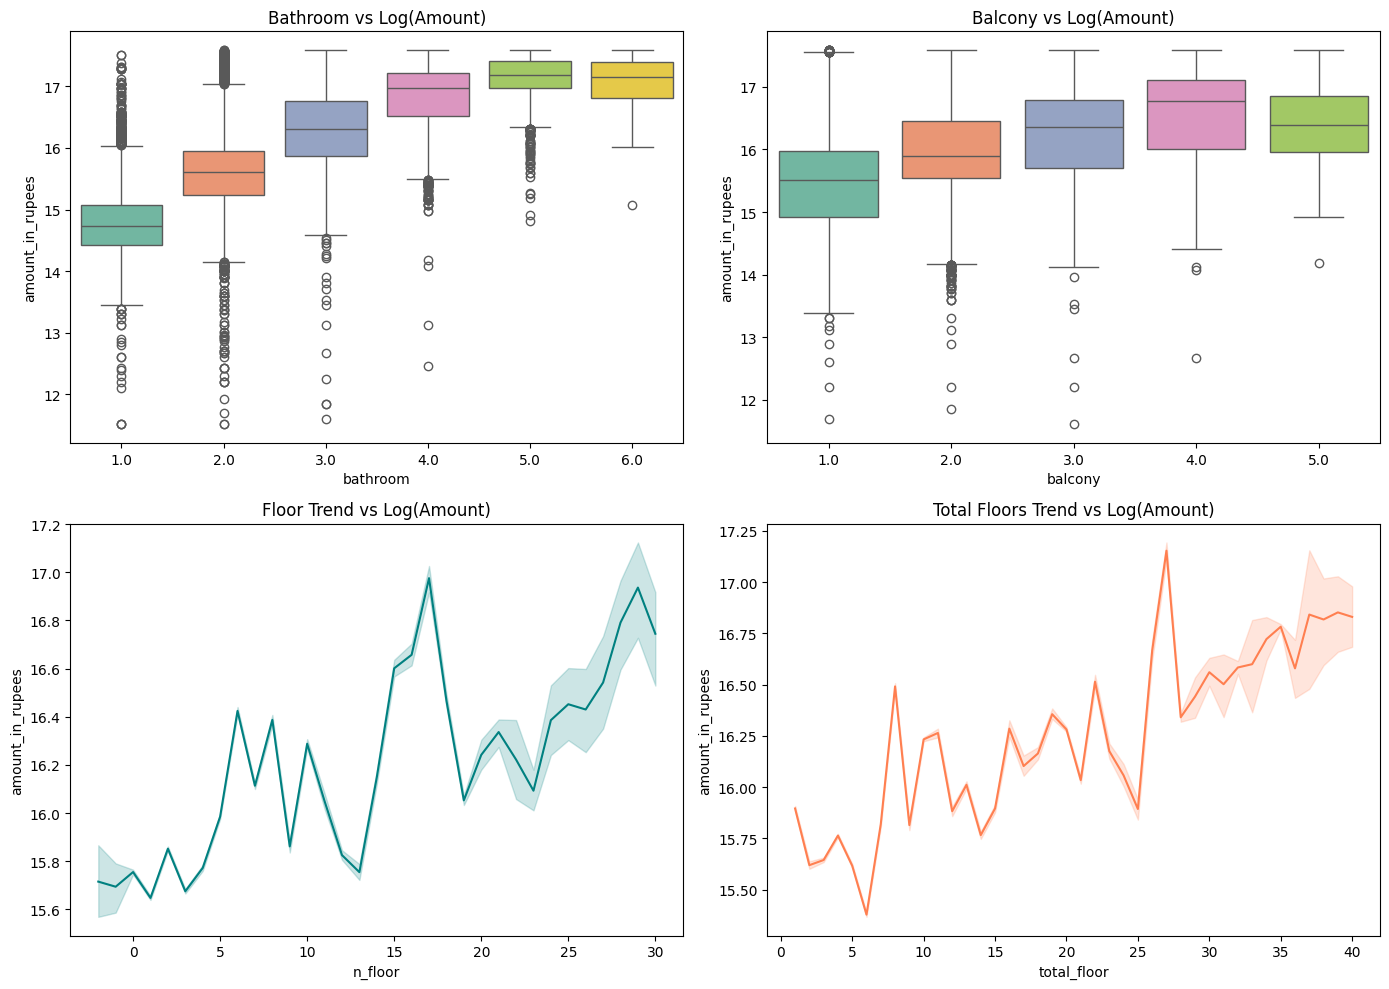

In [143]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=data[data['bathroom'] <= 6], x='bathroom', y=np.log1p(data['amount_in_rupees']), ax=axes[0,0], palette='Set2')
axes[0,0].set_title('Bathroom vs Log(Amount)')


sns.boxplot(data=data[data['balcony'] <= 5], x='balcony', y=np.log1p(data['amount_in_rupees']), ax=axes[0,1], palette='Set2')
axes[0,1].set_title('Balcony vs Log(Amount)')


sns.lineplot(data=data[data['n_floor'] <= 30], x='n_floor', y=np.log1p(data['amount_in_rupees']), ax=axes[1,0], color='teal')
axes[1,0].set_title('Floor Trend vs Log(Amount)')


sns.lineplot(data=data[data['total_floor'] <= 40], x='total_floor', y=np.log1p(data['amount_in_rupees']), ax=axes[1,1], color='coral')
axes[1,1].set_title('Total Floors Trend vs Log(Amount)')

plt.tight_layout()
plt.show()

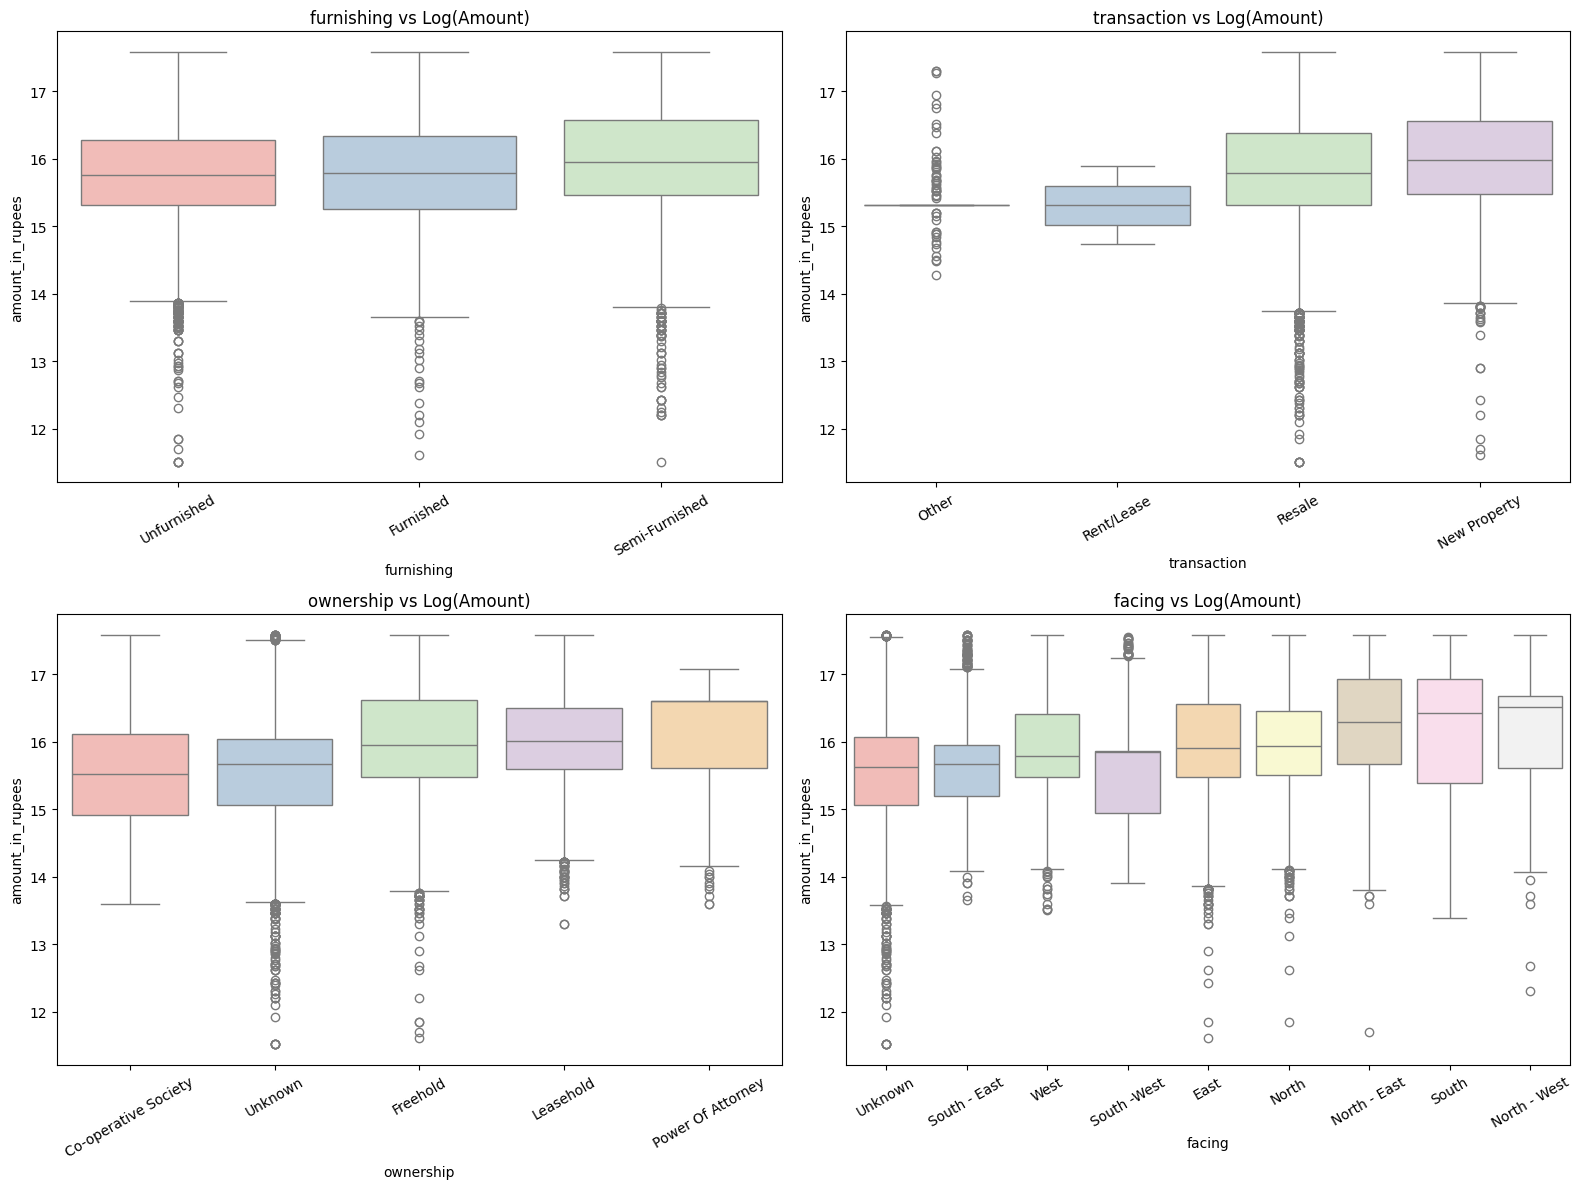

In [144]:
cat_features = ['furnishing', 'transaction', 'ownership', 'facing']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, col in enumerate(cat_features):
    # ترتيب الفئات حسب متوسط السعر لسهولة القراءة
    order = data.groupby(col)['amount_in_rupees'].median().sort_values().index

    sns.boxplot(data=data, x=col, y=np.log1p(data['amount_in_rupees']), order=order, ax=axes[idx], palette='Pastel1')
    axes[idx].set_title(f'{col} vs Log(Amount)')
    axes[idx].set_xticklabels(axes[idx].get_xticklabels(), rotation=30)

plt.tight_layout()
plt.show()

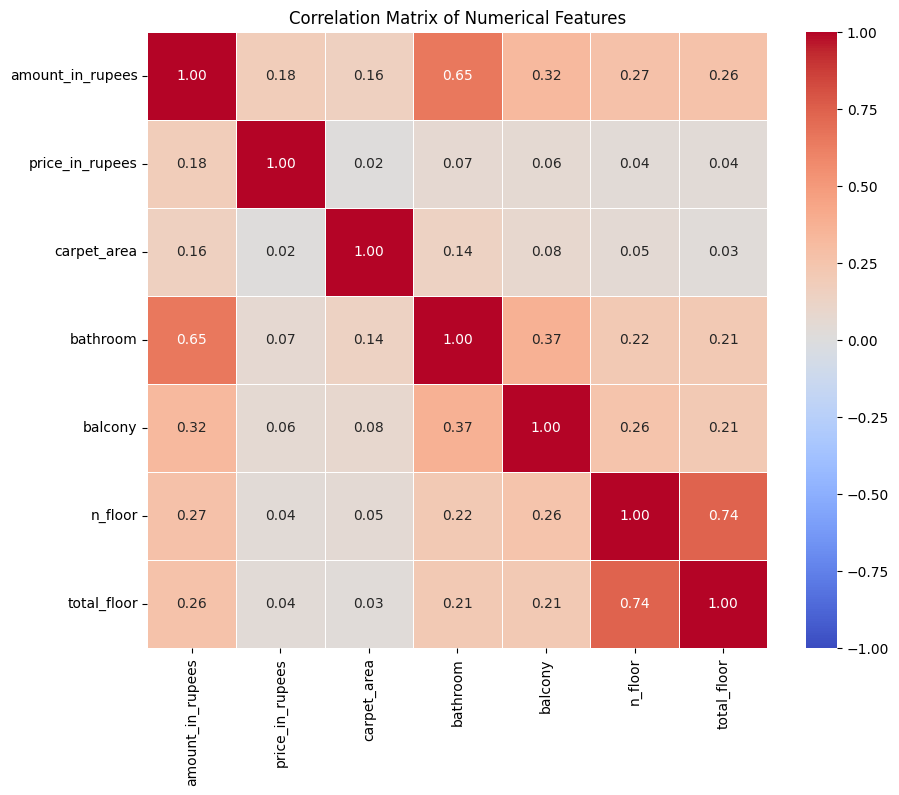

In [145]:

numeric_df = data.select_dtypes(include=[np.number])

plt.figure(figsize=(10, 8))
correlation_matrix = numeric_df.corr()


sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

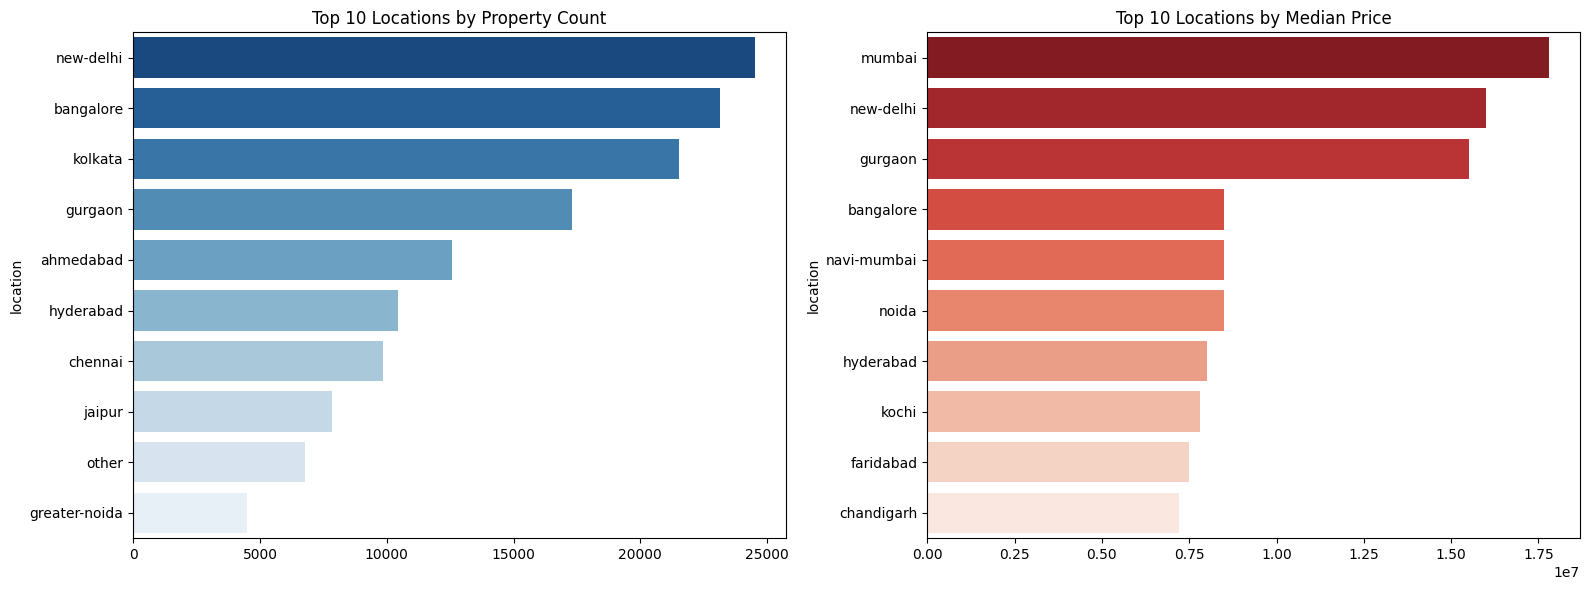

In [146]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))


top_locations_count = data['location'].value_counts().head(10)
sns.barplot(x=top_locations_count.values, y=top_locations_count.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 Locations by Property Count')


top_locations_price = data.groupby('location')['amount_in_rupees'].median().nlargest(10)
sns.barplot(x=top_locations_price.values, y=top_locations_price.index, ax=axes[1], palette='Reds_r')
axes[1].set_title('Top 10 Locations by Median Price')

plt.tight_layout()
plt.show()

# **Feature Engineering**

## Stage 4: Feature Engineering
Preparing features for the model, including scaling, encoding, and creating new variables.

In [147]:
X = data.drop(columns=['amount_in_rupees'])
y = data['amount_in_rupees']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=True, random_state=42
)


In [148]:
carpet_median = X_train[X_train['carpet_area'] > 0]['carpet_area'].median()

X_train['carpet_area'] = X_train['carpet_area'].replace(0, carpet_median)
X_test['carpet_area'] = X_test['carpet_area'].replace(0, carpet_median)

In [149]:

location_price_map = y_train.groupby(X_train['location']).median()


X_train['avg_location_price'] = X_train['location'].map(location_price_map)
X_test['avg_location_price'] = X_test['location'].map(location_price_map)


overall_median = y_train.median()
X_train['avg_location_price'] = X_train['avg_location_price'].fillna(overall_median)
X_test['avg_location_price'] = X_test['avg_location_price'].fillna(overall_median)


X_train = X_train.drop(columns=['price_in_rupees'])
X_test = X_test.drop(columns=['price_in_rupees'])

In [150]:
X_train['floor_ratio'] = X_train['n_floor'] / X_train['total_floor'].replace(0, 1)
X_test['floor_ratio'] = X_test['n_floor'] / X_test['total_floor'].replace(0, 1)

X_train['is_ground_floor'] = (X_train['n_floor'] == 0).astype(int)
X_test['is_ground_floor'] = (X_test['n_floor'] == 0).astype(int)

X_train['is_top_floor'] = (X_train['n_floor'] == X_train['total_floor']).astype(int)
X_test['is_top_floor'] = (X_test['n_floor'] == X_test['total_floor']).astype(int)

In [151]:
bath_median = X_train['bathroom'].median()
X_train['bathroom'] = X_train['bathroom'].fillna(bath_median)
X_test['bathroom'] = X_test['bathroom'].fillna(bath_median)

balcony_mode = X_train['balcony'].mode()[0]
X_train['balcony'] = X_train['balcony'].fillna(balcony_mode)
X_test['balcony'] = X_test['balcony'].fillna(balcony_mode)


X_train['total_amenities'] = X_train['bathroom'] + X_train['balcony']
X_test['total_amenities'] = X_test['bathroom'] + X_test['balcony']


X_train['bath_to_balcony_ratio'] = X_train['bathroom'] / (X_train['balcony'] + 1)
X_test['bath_to_balcony_ratio'] = X_test['bathroom'] / (X_test['balcony'] + 1)

In [152]:
X_train.columns

Index(['location', 'carpet_area', 'transaction', 'furnishing', 'facing',
       'bathroom', 'balcony', 'ownership', 'n_floor', 'total_floor',
       'avg_location_price', 'floor_ratio', 'is_ground_floor', 'is_top_floor',
       'total_amenities', 'bath_to_balcony_ratio'],
      dtype='object')

In [153]:
train_data = pd.concat([X_train, y_train], axis=1)
train_data.shape

(139230, 17)

In [154]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 139230 entries, 133062 to 121958
Data columns (total 17 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   location               139230 non-null  object 
 1   carpet_area            139230 non-null  float64
 2   transaction            139230 non-null  object 
 3   furnishing             139230 non-null  object 
 4   facing                 139230 non-null  object 
 5   bathroom               139230 non-null  float64
 6   balcony                139230 non-null  float64
 7   ownership              139230 non-null  object 
 8   n_floor                139230 non-null  int64  
 9   total_floor            139230 non-null  int64  
 10  avg_location_price     139230 non-null  float64
 11  floor_ratio            139230 non-null  float64
 12  is_ground_floor        139230 non-null  int64  
 13  is_top_floor           139230 non-null  int64  
 14  total_amenities        139230 non-nu

In [155]:
train_data.describe().T

,count,mean,std,min,25%,50%,75%,max
carpet_area,139230.0,1.150908e+03,1.618406e+03,1.0,1.000000e+03,1060.00,1140.00,495970.0
bathroom,139230.0,2.404008e+00,7.982024e-01,1.0,2.000000e+00,2.00,3.00,10.0
balcony,139230.0,1.994405e+00,7.976627e-01,1.0,1.000000e+00,2.00,2.00,6.0
n_floor,139230.0,4.211808e+00,4.512240e+00,-2.0,1.000000e+00,3.00,5.00,40.0
total_floor,139230.0,8.266925e+00,7.209479e+00,1.0,4.000000e+00,5.00,10.00,88.0
avg_location_price,139230.0,8.814603e+06,4.252170e+06,2400000.0,5.200000e+06,7000000.00,8500000.00,17900000.0
floor_ratio,139230.0,5.075453e-01,3.069365e-01,-2.0,2.500000e-01,0.50,0.75,1.0
is_ground_floor,139230.0,9.729943e-02,2.963661e-01,0.0,0.000000e+00,0.00,0.00,1.0
is_top_floor,139230.0,1.230626e-01,3.285102e-01,0.0,0.000000e+00,0.00,0.00,1.0
total_amenities,139230.0,4.398413e+00,1.297045e+00,2.0,4.000000e+00,4.00,5.00,14.0


## Stage 5: Model Prediction & Evaluation
Training various machine learning models and evaluating their performance.

fast seek

In [156]:
'''cat_cols = ['furnishing', 'transaction', 'ownership', 'facing', 'location']

X_train_encoded = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

X_train, X_test = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])'''

"cat_cols = ['furnishing', 'transaction', 'ownership', 'facing', 'location']\n\nX_train_encoded = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)\nX_test_encoded = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)\n\nX_train, X_test = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)\n\nscaler = StandardScaler()\n\nX_train[num_cols] = scaler.fit_transform(X_train[num_cols])\nX_test[num_cols] = scaler.transform(X_test[num_cols])"

In [157]:
'''
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200,max_depth=15,min_samples_leaf=2,random_state=42,n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Evaluate the model
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    print(f'{model_name}:')
    print(f'R-squared: {r2:.2f}')
    print(f'Mean Absolute Error (MAE): {mae:.2f}')
    print(f'Root Mean Squared Error (RMSE): {rmse:.2f}')
    print('----------------------------------------')


'''



"\nmodels = {\n    'Linear Regression': LinearRegression(),\n    'Random Forest': RandomForestRegressor(n_estimators=200,max_depth=15,min_samples_leaf=2,random_state=42,n_jobs=-1),\n    'Gradient Boosting': GradientBoostingRegressor(random_state=42),\n}\n\nfor model_name, model in models.items():\n    model.fit(X_train, y_train)\n    y_pred = model.predict(X_test)\n\n    # Evaluate the model\n    r2 = r2_score(y_test, y_pred)\n    mae = mean_absolute_error(y_test, y_pred)\n    rmse = np.sqrt(mean_squared_error(y_test, y_pred))\n\n    print(f'{model_name}:')\n    print(f'R-squared: {r2:.2f}')\n    print(f'Mean Absolute Error (MAE): {mae:.2f}')\n    print(f'Root Mean Squared Error (RMSE): {rmse:.2f}')\n    print('----------------------------------------')\n\n\n"

In [158]:
num_cols = [
    'carpet_area', 'bathroom', 'balcony', 'n_floor', 'total_floor',
    'avg_location_price', 'floor_ratio', 'total_amenities', 'bath_to_balcony_ratio'
]

cat_cols = ['furnishing', 'transaction', 'ownership', 'facing', 'location']

Modeling with out Log transformation

In [159]:
'''# 1. Feature Lists & Preprocessor

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

#2. Pipelines Definition

pipelines = {
    "LinearRegression": Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ]),
    "RandomForestRegressor": Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(n_estimators=200,max_depth=15,min_samples_leaf=2,random_state=42,n_jobs=-1))
    ]),
    "GradientBoostingRegressor": Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42))
    ])
}
# 3. Model Training & Evaluation

results = []
best_r2 = -float('inf')
best_pipeline = None
best_model_name = ""
best_preds = None

for name, pipeline in pipelines.items():
    # 5-Fold Cross Validation 
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='r2', n_jobs=-1)
    
    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)
    
    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    
    results.append({
        "Model": name,
        "5-Fold CV R2": f"{cv_scores.mean():.4f} (±{cv_scores.std():.4f})",
        "Test R2": round(r2, 4),
        "MAE": f"{mae:,.2f}",
        "RMSE": f"{rmse:,.2f}"
    })
    
    if r2 > best_r2:
        best_r2 = r2
        best_pipeline = pipeline
        best_model_name = name
# 4. Print Results
results_df = pd.DataFrame(results).sort_values(by="Test R2", ascending=False)
print("=== Model Comparison Table ===")
print(results_df.to_string(index=False))'''

=== Model Comparison Table ===
                    Model     5-Fold CV R2  Test R2          MAE         RMSE
    RandomForestRegressor 0.9150 (±0.0022)   0.9164 1,050,109.15 2,446,569.02
GradientBoostingRegressor 0.8906 (±0.0017)   0.8902 1,615,711.83 2,804,187.10
         LinearRegression 0.6021 (±0.0347)   0.6026 3,732,745.65 5,335,331.02


i`m happy to see this amazing result for me => No overfiting , small variance 

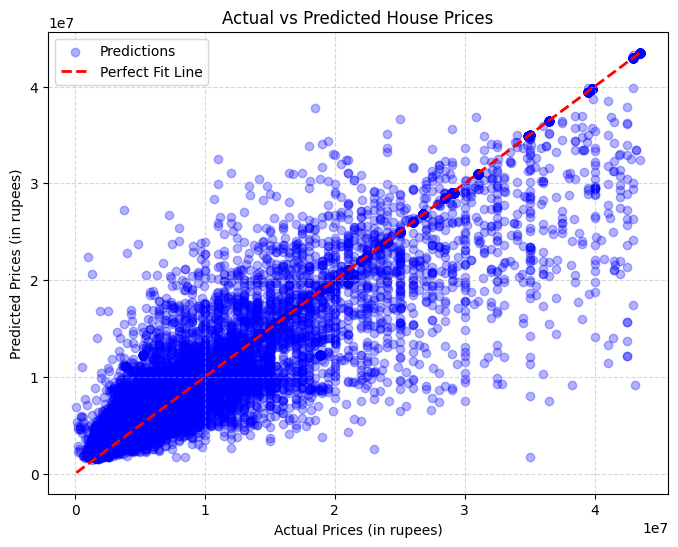

In [161]:
'''preds = best_pipeline.predict(X_test)


plt.figure(figsize=(8, 6))
plt.scatter(y_test, preds, alpha=0.3, color='blue', label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit Line')

plt.xlabel('Actual Prices (in rupees)')
plt.ylabel('Predicted Prices (in rupees)')
plt.title('Actual vs Predicted House Prices')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()'''

In [163]:
'''base_model_filename = "house_price_base.pkl"
joblib.dump(best_pipeline, base_model_filename,compress=3)
print(f"\nSaved Best Base Model to: {base_model_filename}")'''


Saved Best Base Model to: house_price_base.pkl


In [168]:
'''
import json
import joblib


loaded = joblib.load("house_price_base.pkl") 
sample = X_test.iloc[[0]] 

actual_price = y_test.iloc[1]
predicted_price = loaded.predict(sample)[0]
difference = actual_price - predicted_price

print(f"Actual Price: {actual_price:,.2f}")
print(f"Predicted Price: {predicted_price:,.2f}")
print(f"Difference (Error): {difference:,.2f}")



'''

Actual Price: 3,000,000.00
Predicted Price: 2,759,013.13
Difference (Error): 240,986.87


Modeling with Log transformation

In [169]:
'''preprocessor_log = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)


base_models = {
    "LinearRegression": LinearRegression(),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=200,max_depth=15,min_samples_leaf=2,random_state=42,n_jobs=-1),
    "GradientBoostingRegressor": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42)
}

log_pipelines = {}

for name, model in base_models.items():
    log_pipelines[name] = Pipeline([
        ('preprocessor', preprocessor_log),
        ('regressor', TransformedTargetRegressor(
            regressor=model,
            func=np.log1p,      
            inverse_func=np.expm1  
        ))
    ])


log_results = []
best_log_r2 = -float('inf')
best_log_pipeline = None
best_log_model_name = ""

for name, pipeline in log_pipelines.items():
    # 5-Fold Cross Validation - reduce to 2 due to time 
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=2, scoring='r2', n_jobs=-1)
    
  
    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)
    
    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    
    log_results.append({
        "Model": name,
        "5-Fold CV R2": f"{cv_scores.mean():.4f} (±{cv_scores.std():.4f})",
        "Test R2": round(r2, 4),
        "MAE": f"{mae:,.2f}",
        "RMSE": f"{rmse:,.2f}"
    })
    
    if r2 > best_log_r2:
        best_log_r2 = r2
        best_log_pipeline = pipeline
        best_log_model_name = name

log_results_df = pd.DataFrame(log_results).sort_values(by="Test R2", ascending=False)
print("=== Log-Transformed Model Comparison Table ===")
print(log_results_df.to_string(index=False))'''

=== Log-Transformed Model Comparison Table ===
                    Model                        5-Fold CV R2     Test R2           MAE             RMSE
    RandomForestRegressor                    0.9084 (±0.0006)      0.9146    964,580.35     2,473,353.75
GradientBoostingRegressor                    0.8701 (±0.0030)      0.8703  1,679,425.81     3,048,549.77
         LinearRegression -7685140220.9725 (±7685140221.5390) -25434.7535 10,619,541.38 1,349,816,926.55


so i see it the log really make it better a little in low prices error and that good .

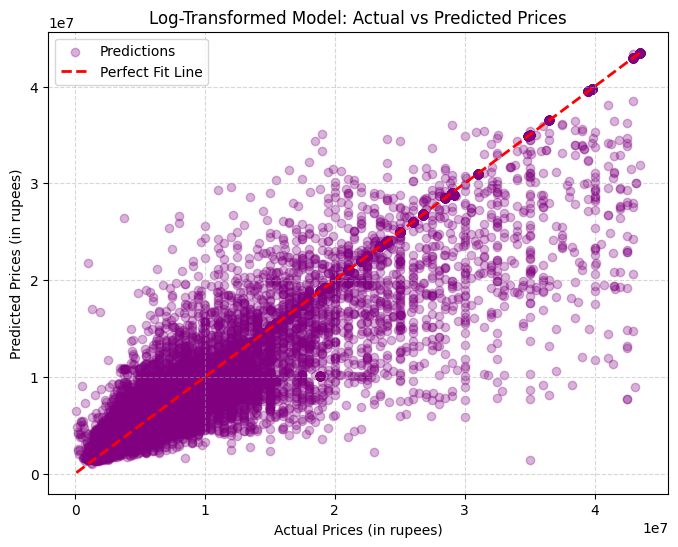

In [171]:
'''
log_preds = best_log_pipeline.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, log_preds, alpha=0.3, color='purple', label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit Line')

plt.xlabel('Actual Prices (in rupees)')
plt.ylabel('Predicted Prices (in rupees)')
plt.title('Log-Transformed Model: Actual vs Predicted Prices')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()'''

In [173]:
'''log_model_filename = "house_price_log.pkl"
joblib.dump(best_pipeline, log_model_filename,compress=3)
print(f"\nSaved Best Log Model to: {log_model_filename}")'''


Saved Best Log Model to: house_price_log.pkl


In [174]:
'''
loaded_log_model = joblib.load("house_price_log.pkl")
sample = X_test.iloc[[0]]

actual_price = y_test.iloc[0]
predicted_price = loaded_log_model.predict(sample)[0]
difference = actual_price - predicted_price

print("\n=== Log Model Single Sample Sanity Check ===")
print(f"Actual Price: {actual_price:,.2f}")
print(f"Predicted Price: {predicted_price:,.2f}")
print(f"Difference (Error): {difference:,.2f}")
'''


=== Log Model Single Sample Sanity Check ===
Actual Price: 3,100,000.00
Predicted Price: 2,759,013.13
Difference (Error): 340,986.87


# So we found the random Forest model is the best for our case with log transformation

In [189]:
# ==========================================
# 1. Preprocessor Construction
# ==========================================
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# ==========================================
# 2. Final Production Pipeline (Log-Transformed RF)
# ==========================================
final_model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', TransformedTargetRegressor(
        regressor=RandomForestRegressor(
            n_estimators=200, 
            max_depth=20,                  # 20 is best practice but more space so i you can reduce it 
            random_state=42, 
            n_jobs=-1
        ),
        func=np.log1p,      # log one
        inverse_func=np.expm1  
    ))
])

# ==========================================
# 3. Model Training & Prediction
# ==========================================
print("Training final Production RandomForest model...")
final_model_pipeline.fit(X_train, y_train)

final_preds = final_model_pipeline.predict(X_test)

# ==========================================
# 4. Model Evaluation Metrics
# ==========================================
r2 = r2_score(y_test, final_preds)
mae = mean_absolute_error(y_test, final_preds)
rmse = np.sqrt(mean_squared_error(y_test, final_preds))

print("\n=== Final Model Performance Evaluation ===")
print(f"Test R2 Score : {r2:.4f}")
print(f"MAE           : {mae:,.2f} Rupees")
print(f"RMSE          : {rmse:,.2f} Rupees")

Training final Production RandomForest model...

=== Final Model Performance Evaluation ===
Test R2 Score : 0.9204
MAE           : 898,883.34 Rupees
RMSE          : 2,388,520.19 Rupees


<h3>The best Score for now and min loss

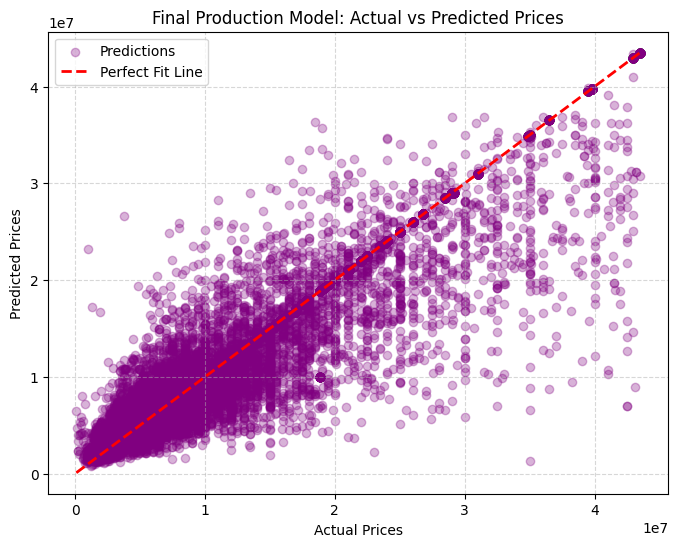

In [190]:
# ==========================================
# 5. Visualization: Actual vs Predicted
# ==========================================
plt.figure(figsize=(8, 6))
plt.scatter(y_test, final_preds, alpha=0.3, color='purple', label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit Line')

plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.title('Final Production Model: Actual vs Predicted Prices')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [191]:
model_filename = "house_price_production_rf.pkl"
joblib.dump(final_model_pipeline, model_filename, compress=3)
print(f"\nModel successfully saved to '{model_filename}' with compress=3!")


Model successfully saved to 'house_price_production_rf.pkl' with compress=3!


In [178]:
# ==========================================
# 6. Sanity Check on Reloaded Model
# ==========================================
loaded_model = joblib.load(model_filename)
sample = X_test.iloc[[0]]

actual_val = y_test.iloc[0]
pred_val = loaded_model.predict(sample)[0]

print("\n=== Reloaded Model Sanity Check ===")
print(f"Actual Price    : {actual_val:,.2f}")
print(f"Predicted Price : {pred_val:,.2f}")
print(f"Difference      : {actual_val - pred_val:,.2f}")


=== Reloaded Model Sanity Check ===
Actual Price    : 3,100,000.00
Predicted Price : 3,108,756.22
Difference      : -8,756.22


<h4> Finally something good <3</h4>

In [192]:
feature_names = final_model_pipeline.named_steps['preprocessor'].get_feature_names_out()
rf_model = final_model_pipeline.named_steps['regressor'].regressor_


feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

feature_importance.head(15)

,Feature,Importance
1,num__bathroom,0.471719
0,num__carpet_area,0.145354
5,num__avg_location_price,0.130248
4,num__total_floor,0.084871
6,num__floor_ratio,0.026892
3,num__n_floor,0.019549
8,num__bath_to_balcony_ratio,0.012675
44,cat__location_kolkata,0.011014
13,cat__transaction_Resale,0.008664
24,cat__facing_Unknown,0.007519
